In [1]:
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
from typing import Annotated
from typing_extensions import TypedDict, Literal
from langgraph.graph.message import add_messages

class MedicalState(TypedDict):
    message: Annotated[list, add_messages]
    next: Literal[
        "diagnostic_agent",
        "physician_review",
        "report_agent",
        "END"
    ]
    question_count: int
    interim_care: str
    diagnostic_summary: str
    physician_treatment: str
    final_report: str

In [3]:
from state import MedicalState
from typing_extensions import Literal
from IPython.display import Markdown


def supervisor(state:MedicalState) -> dict:
    if state.get("final_report"):
        display(Markdown(state["final_report"]))
        return {"next" : "END"}
    if state["question_count"] < 5:
        return {"next" : "diagnostic_agent"}
    if state["question_count"] == 5:
        return {"next" : "report_agent"}



def route_after_supervisor(state: MedicalState) -> Literal["diagnostic_agent","report_agent","END"]:
    return state["next"]
    



In [4]:
from state import MedicalState
from langchain.chat_models import init_chat_model
from langchain_core.messages import SystemMessage


diagnostic_agent_llm = init_chat_model("openai:gpt-5-mini")

MAX_QUESTIONS = 5

DIAGNOSTIC_SYSTEM_PROMPT = (
    "You are a diagnostic intake agent for a medical triage assistant. "
    "Ask the patient exactly one short, clear, relevant question at a time "
    "to understand their symptoms, history, and condition, building on "
    "their previous answers. Reply with only the question itself — no "
    "preamble, no diagnosis, no advice."
)


def DiagnosticAgent(state: MedicalState) -> dict:
    """Asks the patient one diagnostic question per invocation.

    Meant to be called once per question (MAX_QUESTIONS times total): it
    reads the conversation so far from state["message"] (the latest human
    message being the patient's most recent answer) and appends the agent's
    next question as a new AI message, bumping question_count by one.

    Note: diagnostic_summary is NOT produced here. By the time this node
    would see question_count == MAX_QUESTIONS, the patient's answer to the
    final question hasn't been added to state yet, and nothing currently
    calls this node again afterward to pick it up — the supervisor routes
    away as soon as question_count == 5. Summarizing needs its own step
    once the graph wiring (and the supervisor's routing for counts 1-4,
    which it doesn't handle yet either) is decided.
    """
    question_count = state.get("question_count", 0)
    history = [SystemMessage(content=DIAGNOSTIC_SYSTEM_PROMPT), *state["message"]]

    if question_count == MAX_QUESTIONS - 1:
        history.append(SystemMessage(
            content="This is the final question — after it, no more will be asked."
        ))

    question = diagnostic_agent_llm.invoke(history)

    print(question.content)
    return {
        "message": [question],
        "question_count": question_count + 1,
    }


In [5]:
from ddgs import DDGS
from langchain.tools import tool


@tool
def web_search(query: str, num_results:int=5) -> str:
    """
        Search the web usin DuckDuckGo
        Args:
        query : Search query string
            num_results : Number of results to return (Default=5)
        Returns:
        Formatted search results with titles, descptions and Urls
    """
    try:
        print(f'Search tool is called for {query}')
        ddgs_search = DDGS()
        results=ddgs_search.text(query=query, max_results=num_results, backend="google")
        if not results:
            return f"No results found for {query} "
        formatted_results = [f"Search for {query} : \n"]
        for i, result in enumerate(results,1):
            title = result.get("title","No Title")
            body = result.get("body","No description available")
            href = result.get("href","")
        formatted_results.append( f"{i}. **{title}**. {body}. {href}")
        return formatted_results
    except Exception as e:
        print(str(e))

In [6]:
report_agent_llm = init_chat_model("openai:gpt-5-mini").bind_tools([web_search])

REPORT_AGENT_PROMPT= "You are a reporter agent, your job is to generate a report about the patient situation based on {messages} propose solutions and medicaments."

def report_agent(state:MedicalState) -> dict:
    """
        You are a reporter agent, your job is to genarte a report to the patient
    """
    messages = state["message"]
    entretien = ""
    print("Inside the report agent")
    for p in messages:
        entretien = entretien+" "+p.content
    report = report_agent_llm.invoke(REPORT_AGENT_PROMPT.format(messages=entretien))
    state["question_count"] = state["question_count"] + 10
    return {"final_report":report.content}
    

In [7]:
from langchain_core.messages import HumanMessage


def PatientResponse(state: MedicalState) -> dict:
    """Prompts the patient for their answer to the last question asked
    and stores it in state["message"] as a new human message.
    """
    answer = input("Your answer: ")
    return {"message": [HumanMessage(content=answer)]}

In [8]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, Markdown, display

builder = StateGraph(MedicalState)
builder.add_node("supervisor",supervisor)
builder.add_node("report_agent",report_agent)
builder.add_node("diagnostic_agent",DiagnosticAgent)
builder.add_edge(START, "supervisor")
builder.add_conditional_edges(
    "supervisor",
    route_after_supervisor,
    {
        "diagnostic_agent": "diagnostic_agent",
        "report_agent": "report_agent",
        "END": END,
    },
)
builder.add_node("patient_response", PatientResponse)
builder.add_edge("diagnostic_agent", "patient_response")
builder.add_edge("patient_response", "supervisor")
builder.add_edge("report_agent","supervisor")



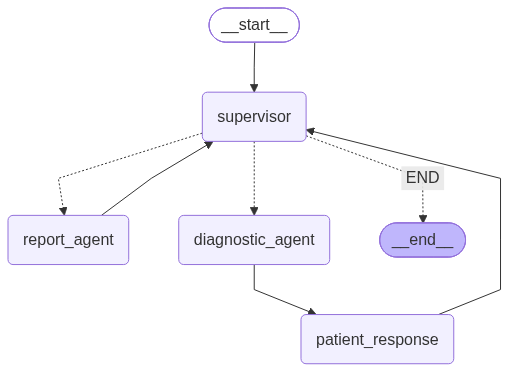

In [9]:
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [10]:
result = graph.invoke({"message": [], "question_count": 0})

What is the main symptom or problem you are experiencing right now?
What is the main symptom or problem you are experiencing right now?
Does this difficulty occur during partnered sex, during masturbation, or both?
Does this difficulty occur during partnered sex, during masturbation, or both?
How long have you been experiencing difficulty reaching orgasm during partnered sex?
Inside the report agent


Patient report — difficulty reaching orgasm during partnered sex

Source: Patient report (self)
- Main problem: Difficulty reaching orgasm.
- Context: Occurs during partnered sex (not during masturbation).
- Duration: Began about 3 months ago, since marriage.
- Additional information needed: Patient sex/gender, age, medical history, medications, mental-health history, alcohol/recreational drug use, partner factors, whether orgasm is achieved during masturbation, details about arousal/erection/lubrication, prior sexual function.

Brief summary / working impression
- This is a new-onset orgasm difficulty confined to partnered sex. That pattern commonly reflects psychological/relationship factors (performance anxiety, stress, new relationship dynamics, expectations), but can also result from physical or iatrogenic causes (medications such as SSRIs, hormonal changes, neurologic disease, diabetes, pelvic surgery, substance use) or partner/technique factors.
- Because orgasm happens during masturbation (you implied it does by not saying otherwise), a strong clue points toward situational/psychological causes rather than a global physiologic inability — though I need explicit confirmation.

Likely causes (differential diagnosis)
1. Psychological/relational
   - Performance anxiety, stress about pleasing partner, guilt, new sexual routine, differences in sexual technique or timing.
   - Relationship factors: poor communication, unresolved conflict.
   - Past sexual trauma (if present).
2. Medication-related
   - Antidepressants (SSRIs, SNRIs), some antipsychotics, certain antihypertensives, opiates, etc., can delay or prevent orgasm.
3. Hormonal or medical
   - Low testosterone (in men), thyroid dysfunction, diabetes (neuropathy), neurological disease.
4. Sexual technique/arousal mismatch
   - Insufficient foreplay, inadequate clitoral stimulation (for many women), partner technique or position not providing needed stimulation.
5. Substance use
   - Alcohol, cannabis, recreational drugs can impair orgasm.
6. Other
   - Pelvic floor dysfunction (either hypertonic or hypotonic), pain during intercourse, or vascular issues.

Recommended initial evaluation (what a clinician should assess)
- Clarify sex/gender and whether orgasm occurs with masturbation (you said difficulty during partnered sex only — please confirm).
- Full sexual history: arousal, erection/lubrication, ejaculation timing, orgasm quality, pain, partner factors.
- Medication list (especially antidepressants, antipsychotics, beta-blockers, opioids, hormonal therapies).
- Medical history: diabetes, neurologic disease, pelvic surgery, endocrine disorders.
- Mental-health screen: depression, anxiety, PTSD.
- Substance and alcohol use.
- Physical exam (general, focused neurologic and genitourinary or pelvic as appropriate).
- Basic labs if indicated: fasting glucose/HbA1c, TSH, morning testosterone (men), others depending on history.

Non‑pharmacologic interventions (first-line for many patients)
- Open communication with partner: discuss what works, what stimulation you need, pacing and expectations.
- Increase foreplay and focused genital stimulation (e.g., direct clitoral stimulation for many women; manual or oral stimulation; use of sex toys or a vibrator if acceptable).
- Sensate-focus exercises with partner (structured intimacy exercises to reduce performance pressure).
- Masturbation training: practice the type/intensity/timing of stimulation you use alone and then communicate or mimic that during partnered sex.
- Schedule sex when relaxed and not rushed; reduce alcohol beforehand.
- Reduce performance pressure: avoid viewing intercourse solely as goal-directed (orgasm = success).
- Pelvic floor physiotherapy (if pelvic tension or pain suspected).
- Couples or sex therapy with a certified sex therapist or psychologist if psychological or relationship factors exist.
- Address sleep, stress, and general health: exercise, sleep hygiene, limit recreational drug use.

Medication / medical management (to be discussed with a prescribing clinician)
Important: Do not stop or change prescription medicines without first discussing with your prescriber.

- If the patient is taking SSRIs/SNRIs or other meds associated with orgasmic delay:
  - Review options with the prescriber: dose reduction, drug holiday (rarely used and must be supervised), switching to an antidepressant with lower sexual side effects (e.g., bupropion) or using adjunctive treatments. Any change requires clinician oversight.
- Pharmacologic adjuncts (off‑label or variable evidence):
  - Bupropion has some evidence for improving SSRI-induced sexual dysfunction (discuss with prescriber).
  - In certain cases, dopaminergic agents or amantadine have been used for delayed ejaculation, but evidence is limited.
  - Sildenafil or other PDE5 inhibitors are sometimes tried for female sexual arousal disorder (not specifically for orgasm) — evidence is mixed.
  - Topical vibratory stimulation or local devices can be effective for some people, particularly when direct stimulation is needed.
  - Hormone therapy: if testing shows low testosterone (men) or significant endocrine abnormalities, targeted replacement or treatment may be appropriate.
  - Note: There are no guaranteed pharmacologic cures for orgasmic disorder; medication strategies depend on cause and have varying success and potential side effects.
- Referral to specialist (before starting meds):
  - Primary care or the prescribing physician to review current meds and general health.
  - Urology (men) or gynecology (women) for focused evaluation if a physical cause suspected.
  - Endocrinology if hormonal abnormalities.
  - Sex therapist/psychologist for structured behavioral therapy.

Immediate steps you can take now
1. Confirm whether you can reach orgasm during masturbation — if yes, focus on using that stimulation pattern with your partner and communicate it.
2. Talk openly with your partner about techniques and reduce pressure to “perform.”
3. Try sensate-focus and extended foreplay; incorporate vibrators if comfortable.
4. Cut back on alcohol and recreational drugs before sex.
5. Make an appointment with your primary care physician to review medications and check basic labs (blood glucose, thyroid, testosterone if male).
6. Consider a short course of couples or sex therapy if there is relationship stress or performance anxiety.

When to seek prompt medical attention / red flags
- New neurologic symptoms (numbness, weakness).
- Sudden changes after surgery or new medication.
- Signs of major depression or suicidal thoughts — seek urgent mental-health care.
- Painful intercourse, penile or genital lesions, or other acute genital symptoms.

Suggested next questions for you (so I can tailor the plan)
1. What is your sex/gender and age?
2. Can you reach orgasm during masturbation? (Yes / No / Sometimes)
3. Are you taking any prescription medications (especially antidepressants, antipsychotics, blood pressure meds, opioids)?
4. Any medical problems (diabetes, thyroid disease, surgeries)?
5. Alcohol or recreational drug use?
6. Any history of sexual trauma, major stress, or relationship conflict?
7. Do you and your partner have sex frequently or is it new/less frequent since marriage?

If you want, I can draft a short script you can use to talk with your partner or a checklist to take to your clinician. I can also outline sensate-focus steps or specific behavioral exercises.